# **Data Exploration and Preprocessing**

## **Notebook Index**

* [Imports and Data Overview](01_introduction.ipynb)
* [Exploratory Data Analysis](02_data_exploration_and_preprocessing.ipynb)
* [Preprocessing](03_genre_identification.ipynb)


## **Imports and Data Overview**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

c:\Users\lucas\.conda\envs\text-mining1\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
train_data = pd.read_csv('../data/train.csv')
test_data = pd.read_csv('../data/test.csv')
display(train_data.head())
display(test_data.head())

,title,tag,artist,year,views,features,lyrics,id
0,Walk Away,rock,Tony Molina,2013,699,{},When you said you loved me\nDid you mean it th...,535805
1,Gotta Make It Kid Naruto Rap,rap,Reece Lett,2021,4,{Sl!ck},Kid Naruto Rap\n[Hook]\nEverybody wants you to...,7519483
2,​this is what i asked for,pop,Elliot (DNK),2019,389,{},[Verse 1]\nPeople tell me I've changed\nI find...,4892808
3,Stealing Hearts,pop,Katie Armiger,2013,126,{},You've been warned about me\nDon't try to get ...,1584150
4,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\nI can see the end is coming but I’v...,7639050


,title,artist,year,views,features,lyrics,id
0,Like You Do,Jimmie Allen,2018,825,{},[Verse 1]\nYour head's on my chest\nThis bed's...,3996359
1,This Building is Falling Down,The Taxpayers,2009,400,{},Epilogue: A sound off from simple people with ...,3553166
2,My Private Joy,Dion and The Belmonts,1960,229,{},[Verse 1]\nOh well Susie is a doozy with a pon...,2998742
3,Vegan,Yung Kurry,2018,1041,{},Hook\nShe a vegan but she eat my meat with no ...,3993470
4,To The Boy I Used To Know,Angelina Cruz,2018,63,{},To the boy I used to know\nI wonder how do you...,5488256


In [3]:
train_data.shape, test_data.shape

((134967, 8), (33742, 7))

In [4]:
train_data.info()
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134967 entries, 0 to 134966
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   title     134965 non-null  object
 1   tag       134967 non-null  object
 2   artist    134967 non-null  object
 3   year      134967 non-null  int64 
 4   views     134967 non-null  int64 
 5   features  134967 non-null  object
 6   lyrics    134967 non-null  object
 7   id        134967 non-null  int64 
dtypes: int64(3), object(5)
memory usage: 8.2+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33742 entries, 0 to 33741
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   title     33742 non-null  object
 1   artist    33742 non-null  object
 2   year      33742 non-null  int64 
 3   views     33742 non-null  int64 
 4   features  33742 non-null  object
 5   lyrics    33742 non-null  object
 6   id        33742 non-null  int64 


In [5]:
display(train_data.describe())
display(test_data.describe())

,year,views,id
count,134967.000000,1.349670e+05,1.349670e+05
mean,2009.467537,3.413344e+03,3.593871e+06
std,46.287743,4.192449e+04,2.323217e+06
min,1.000000,0.000000e+00,2.800000e+01
25%,2008.000000,2.200000e+01,1.414202e+06
50%,2015.000000,8.900000e+01,3.547995e+06
75%,2019.000000,4.730000e+02,5.600458e+06
max,2024.000000,3.604497e+06,7.882826e+06


,year,views,id
count,33742.000000,3.374200e+04,3.374200e+04
mean,2009.649606,3.712460e+03,3.604763e+06
std,40.044269,5.384800e+04,2.323315e+06
min,1.000000,0.000000e+00,7.000000e+00
25%,2008.000000,2.200000e+01,1.421414e+06
50%,2015.000000,8.800000e+01,3.564637e+06
75%,2019.000000,4.600000e+02,5.604923e+06
max,2023.000000,6.877777e+06,7.882715e+06


### **Missing values**

In [6]:
display(train_data.isna().sum())
display(test_data.isna().sum())

title       2
tag         0
artist      0
year        0
views       0
features    0
lyrics      0
id          0
dtype: int64

title       0
artist      0
year        0
views       0
features    0
lyrics      0
id          0
dtype: int64

### **Duplicates**

In [7]:
train_data.duplicated().sum()

0

### **Takeaways from initial data exploration**
 - There's clearly unrealistic values in the 'year' column, to be explored in EDA.
 - We only have 2 missing values, both from the 'title' column in the training data. These will be handled in the preprocessing.



## **Exploratory Data Analysis**

### **Lyrics Word Count**

Looking at the length for each song's lyrics.

In [9]:
# Using a copy to avoid creating a feature on the original dataset
train_data_copy = train_data.copy()

train_data_copy['lyrics_wordcount'] = train_data_copy['lyrics'].apply(lambda x: len(x.split()))
train_data_copy['lyrics_wordcount'].describe()

count    134967.000000
mean        317.614017
std         451.526740
min           1.000000
25%         158.000000
50%         244.000000
75%         377.000000
max       18221.000000
Name: lyrics_wordcount, dtype: float64

There's some clear outliers from the lyrics length, as there's an extreme maximum wordcount. The upcoming plots will have a 1500 word limit (defined by the group logically), and the outliers will be dealt with in the preprocessing.

### **Genre Analysis**

Checking the 'tag' column distribution in the training set to understand genres' popularity.

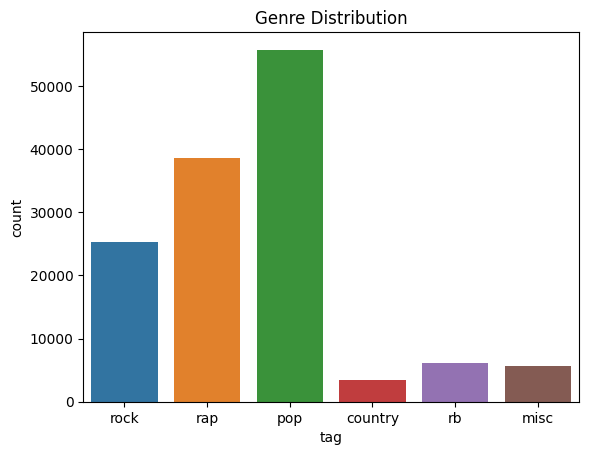

In [8]:
sns.countplot(data=train_data, x='tag')
plt.title ('Genre Distribution')
plt.show()

Plots to check other variables' distribution when separated by genre.

In [ ]:
# Creating a log-scaled views column, as popularity is highly skewed
train_data_copy['log_views'] = np.log1p(train_data_copy['views'])

# Genre ordering by values count and palette 
genres = ['pop', 'rap', 'rock', 'rb', 'misc', 'country']
colors = {'pop': '#636EFA', 'rap': '#EF553B', 'rock': '#00CC96',
        'rb': '#AB63FA', 'misc': '#FFA15A', 'country': '#19D3F3'}

# 3 subplots grid
fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=(
        '<b>1. Release Year (1960–2024)</b>',
        '<b>2. Lyrics Word Count</b>',
        '<b>3. Popularity (log-scaled)</b>'), shared_yaxes=True)

for g in genres:
    sub_all = train_data_copy[train_data_copy['tag'] == g]
    
    # Year vs Genre
    fig.add_trace(go.Box(
        x=sub_all['year'][sub_all['year'] > 1950], y=sub_all['tag'], name=g,
        orientation='h', marker_color=colors[g],
        boxpoints=False, showlegend=False
    ), row=1, col=1)
    
    # Lyrics Length vs Genre
    fig.add_trace(go.Box(
        x=sub_all['lyrics_wordcount'][sub_all['lyrics_wordcount'] < 1500], y=sub_all['tag'], name=g,
        orientation='h', marker_color=colors[g],
        boxpoints=False, showlegend=False
    ), row=1, col=2)
    
    # Log Views vs Genre
    fig.add_trace(go.Box(
        x=sub_all['log_views'], y=sub_all['tag'], name=g,
        orientation='h', marker_color=colors[g],
        boxpoints=False, showlegend=False
    ), row=1, col=3)

# Layout
fig.update_layout(
    title_text='<b>Cross-Genre Comparisons</b>',
    height=500,
    width=1000,
    template='plotly_white',
    margin=dict(l=60, r=40, t=80, b=50))

fig.update_xaxes(title_text='Year', row=1, col=1)
fig.update_xaxes(title_text='Word Count', row=1, col=2)
fig.update_xaxes(title_text='log(1 + views)', row=1, col=3)
fig.show()

### **Year and Wordcount Anomalies**

From the dataset overview, we identified a low minimum on the 'year' column, so we're going to analyze all songs from before 1900 (clear outliers) by genre to try and find a pattern.

In [44]:
train_data.loc[train_data['year'] < 1900, 'tag'].value_counts() 

tag
misc       590
rap         34
pop         18
rb           6
rock         4
country      1
Name: count, dtype: int64

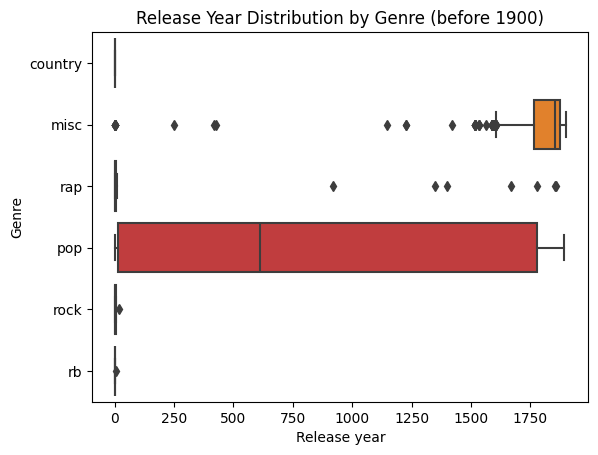

In [43]:
sns.boxplot(data=train_data.loc[train_data['year'] < 1900], x='year', y='tag')
plt.title('Release Year Distribution by Genre (before 1900)')
plt.xlabel('Release year')
plt.ylabel('Genre')
plt.show()

The majority of the values found correspond to the miscellaneous genre, which is condensed in the zone right before our cut off. However, other genres have release at almost year 0, except pop, which is spread accross the board.

## **Preprocessing** - é preciso decidir bem o tradeoff com a sentiment analysis

### **Basic Text Cleaning**

The raw text is standardized to ensure accurate word counts for outlier identification and to prepare the upcoming preprocessing steps. The standardization includes **ISTO TUDO PODE MUDAR PA SENTIMENT ANALYSIS**:
 - Lowercasing: converted all text to lowercase.
 - Noise Removal: stripped newline characters, HTML artifacts and non-alphanumeric punctuation with no value (, . ; :). **NAO TIRAR ALGUMA PONTUACAO COM VALOR SENTIMENTAL.  regex com plo menos ponto de exclamacao e interrogacao: r'[^\w\s!?]'**
 - Tag Handling: the lyrics include specific section tags (such as [Introduction] or [Chorus]). **DECIDIR O QUE FAZER COM ISTO**

### **Outlier Handling**

### **Stopword Strategy**

### **Vectorization**

### **Data Normalization and Scaling**